In [1]:
import geopandas as gpd
import rasterio
import shapely

print("geopandas", gpd.__version__)
print("rasterio ", rasterio.__version__, "| GDAL", rasterio.__gdal_version__)
print("shapely  ", shapely.__version__)

geopandas 1.2.0
rasterio  1.5.2 | GDAL 3.12.2
shapely   2.2.0


# Część B: Rasterio — dane rastrowe i NDVI

**Scenariusz:** Prawdziwa scena Sentinel-2 L2A z 6 października 2026 r. (Opole i okolice), pobrana z Copernicus Browser jako dwa pliki:
- `B04` = Red (665 nm)
- `B08` = NIR (842 nm)

Chcemy policzyć wskaźnik roślinności **NDVI** i sprawdzić, które dzielnice Opola mają najwięcej zieleni:

$$\text{NDVI} = \frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red}} = \frac{B08 - B04}{B08 + B04} \in [-1, 1]$$

| Zakres NDVI | Typowe pokrycie terenu |
|---|---|
| `< 0` | Woda |
| `0 – 0.2` | Zabudowa, goła gleba |
| `0.2 – 0.5` | Rzadka / słaba roślinność |
| `> 0.5` | Gęsta, zdrowa roślinność |

**B1. Konfiguracja ścieżek i import bibliotek**

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
from rasterio.warp import transform, calculate_default_transform, reproject, Resampling
from rasterio.io import MemoryFile
import rasterio.mask

DATA_DIR = Path("dane")
OUT_DIR = Path("wyniki")
OUT_DIR.mkdir(exist_ok=True)

B04_PATH = DATA_DIR / "S2_L2A_2026-10-06_B04.tiff"
B08_PATH = DATA_DIR / "S2_L2A_2026-10-06_B08.tiff"
DISTRICTS_PATH = DATA_DIR / "opole_districts.geojson"

for p in [B04_PATH, B08_PATH, DISTRICTS_PATH]:
    print(f"{p}: {'OK' if p.exists() else 'BRAK PLIKU'}")

dane/S2_L2A_2026-10-06_B04.tiff: OK
dane/S2_L2A_2026-10-06_B08.tiff: OK
dane/opole_districts.geojson: OK


**B2. Otwarcie pliku i metadane**

Samo otwarcie pliku przez `rasterio.open(...)` w bloku `with` nie wczytuje pikseli — metadane czytamy błyskawicznie nawet dla bardzo dużych scen.

In [3]:
with rasterio.open(B04_PATH) as src:
    print("=== B04 (Red) ===")
    print("Profile:", src.profile)
    print("CRS:    ", src.crs)
    print("Bounds: ", src.bounds)
    print("Res:    ", src.res)
    print("Shape:  ", src.shape)
    print("Nodata: ", src.nodata)
    print("Tags:   ", src.tags())

with rasterio.open(B08_PATH) as src:
    print("\n=== B08 (NIR) ===")
    print("CRS:    ", src.crs)
    print("Bounds: ", src.bounds)
    print("Res:    ", src.res)
    print("Shape:  ", src.shape)
    print("Nodata: ", src.nodata)

=== B04 (Red) ===
Profile: {'driver': 'GTiff', 'dtype': 'float32', 'nodata': None, 'width': 2083, 'height': 1717, 'count': 1, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'), 'transform': Affine(8.999231877100454e-05, 0.0, 17.895355,
       0.0, -8.998019801979886e-05, 50.74558), 'blockxsize': 2083, 'blockysize': 8, 'tiled': False, 'compress': 'deflate', 'interleave': 'band'}
CRS:     EPSG:4326
Bounds:  BoundingBox(left=17.895355, bottom=50.591084, right=18.082809, top=50.74558)
Res:     (8.999231877100454e-05, 8.998019801979886e-05)
Shape:   (1717, 2083)
Nodata:  None
Tags:    {'TIFFTAG_XRESOLUTION': '1', 'TIFFTAG_YRESOLUTION': '1', 'TIFFTAG_RESOLUTIONUNIT': '1 (unitless)', 'AREA_OR_POINT': 'Area'}

=== B08 (NIR

**B3. Piksel ↔ współrzędne**

Transformacja afiniczna (`src.transform`) mapuje indeksy `(row, col)` na współrzędne terenowe `(x, y)`. Dzięki `window=` możemy odczytać tylko wybrany fragment rastra bez ładowania całej sceny do pamięci.

In [4]:
# Przykładowe współrzędne WGS 84 (Opole)
lon, lat = 17.989082, 50.668332

with rasterio.open(B04_PATH) as red_src, rasterio.open(B08_PATH) as nir_src:
    print("Transformacja afiniczna B04:\n", red_src.transform)

    # Przeliczenie WGS 84 (lon, lat) -> CRS rastra
    (x,), (y,) = transform("EPSG:4326", red_src.crs, [lon], [lat])
    row, col = red_src.index(x, y)
    px_x, px_y = red_src.xy(row, col)

    red_val = red_src.read(1, window=((row, row + 1), (col, col + 1)))[0, 0]
    nir_val = nir_src.read(1, window=((row, row + 1), (col, col + 1)))[0, 0]
    ndvi_pt = (nir_val - red_val) / (nir_val + red_val) if (nir_val + red_val) != 0 else np.nan

    print(f"Punkt (lon, lat) = ({lon}, {lat})")
    print(f"Indeks piksela (row, col) = ({row}, {col})")
    print(f"Środek piksela (x, y) = ({px_x:.6f}, {px_y:.6f})")
    print(f"Red (B04) = {red_val:.4f}, NIR (B08) = {nir_val:.4f}, NDVI = {ndvi_pt:.3f}")

Transformacja afiniczna B04:
 | 0.00, 0.00, 17.90|
| 0.00,-0.00, 50.75|
| 0.00, 0.00, 1.00|
Punkt (lon, lat) = (17.989082, 50.668332)
Indeks piksela (row, col) = (858, 1041)
Środek piksela (x, y) = (17.989082, 50.668332)
Red (B04) = 0.0620, NIR (B08) = 0.2895, NDVI = 0.647


**B4. Odczyt pasm, statystyki i histogramy**

Używamy `masked=True`, aby piksele `nodata` zostały automatycznie zamaskowane w tablicy `MaskedArray` (statystyki NumPy ignorują wtedy `nodata`).

Red (B04): min=0.0000, max=1.5514, mean=0.0571, nodata_px=0
NIR (B08): min=0.0000, max=1.5103, mean=0.2013, nodata_px=0


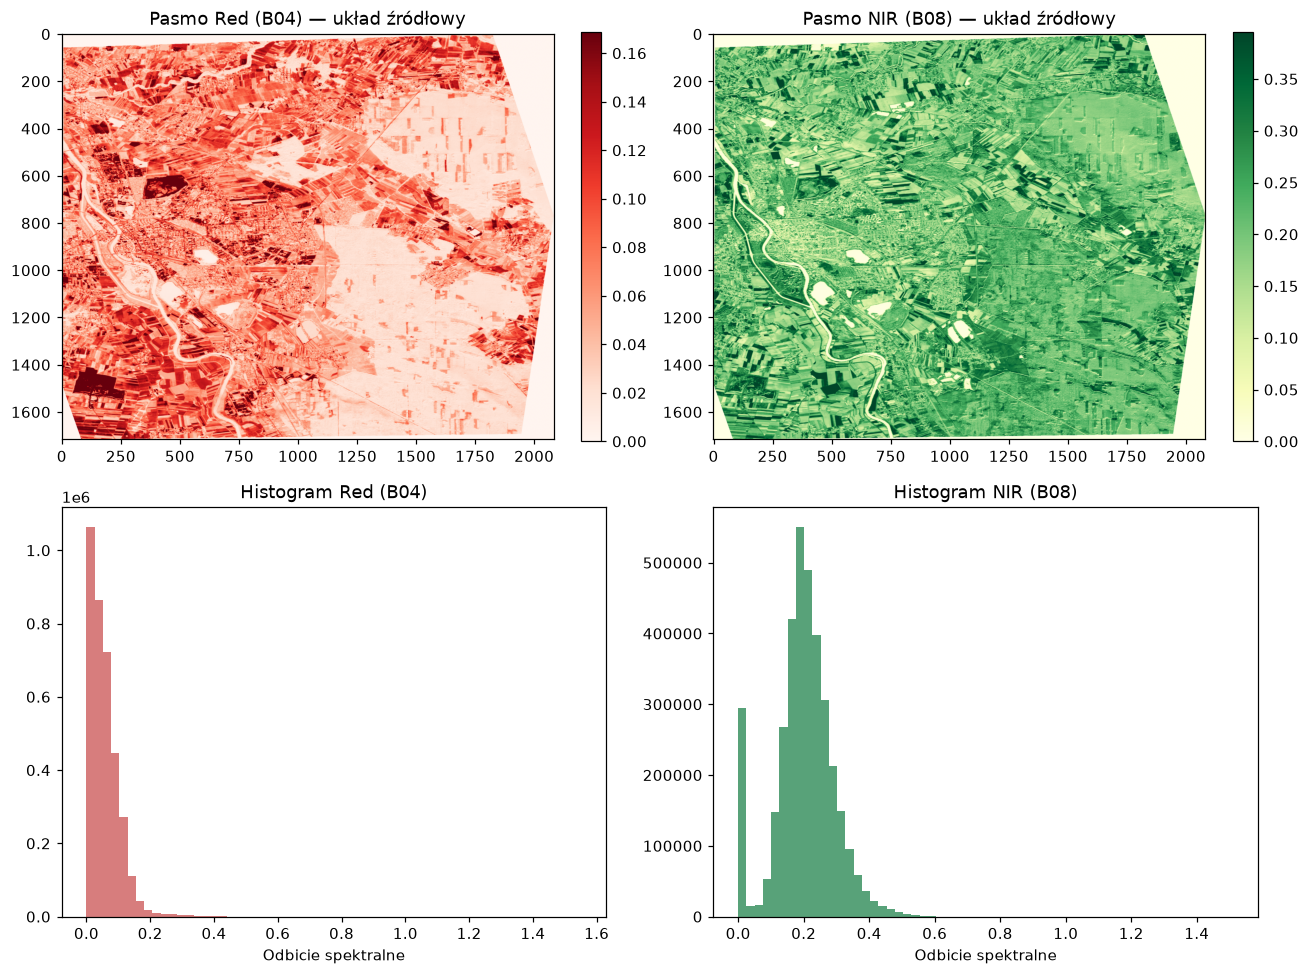

In [5]:
with rasterio.open(B04_PATH) as src:
    red_raw = src.read(1, masked=True).astype("float32")

with rasterio.open(B08_PATH) as src:
    nir_raw = src.read(1, masked=True).astype("float32")

for name, arr in [("Red (B04)", red_raw), ("NIR (B08)", nir_raw)]:
    print(
        f"{name}: min={arr.min():.4f}, max={arr.max():.4f}, "
        f"mean={arr.mean():.4f}, nodata_px={int(np.ma.count_masked(arr))}"
    )

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

im0 = axes[0, 0].imshow(red_raw, cmap="Reds", vmin=0, vmax=np.percentile(red_raw.compressed(), 98))
axes[0, 0].set_title("Pasmo Red (B04) — układ źródłowy")
plt.colorbar(im0, ax=axes[0, 0], fraction=0.046)

im1 = axes[0, 1].imshow(nir_raw, cmap="YlGn", vmin=0, vmax=np.percentile(nir_raw.compressed(), 98))
axes[0, 1].set_title("Pasmo NIR (B08) — układ źródłowy")
plt.colorbar(im1, ax=axes[0, 1], fraction=0.046)

axes[1, 0].hist(red_raw.compressed(), bins=60, color="indianred", alpha=0.8)
axes[1, 0].set_title("Histogram Red (B04)")
axes[1, 0].set_xlabel("Odbicie spektralne")

axes[1, 1].hist(nir_raw.compressed(), bins=60, color="seagreen", alpha=0.8)
axes[1, 1].set_title("Histogram NIR (B08)")
axes[1, 1].set_xlabel("Odbicie spektralne")

plt.tight_layout()
plt.show()

**B5. Wspólna siatka w metrach (reprojekcja do EPSG:2180)**

Algebra rastrowa (`nir - red`) działa piksel w piksel — oba rastry muszą mieć identyczną siatkę. Dodatkowo do obliczeń powierzchni potrzebujemy układu metrycznego (`EPSG:2180`, piksel 10 × 10 m).

In [6]:
dst_crs = "EPSG:2180"

with rasterio.open(B04_PATH) as red_src, rasterio.open(B08_PATH) as nir_src:
    same_grid = (
        red_src.crs == nir_src.crs
        and red_src.transform == nir_src.transform
        and red_src.shape == nir_src.shape
    )
    print("Czy pasma wejściowe mają identyczną siatkę?", same_grid)
    print(f"Przed: {red_src.crs}, kształt={red_src.shape}, piksel={red_src.res}")

    dst_transform, width, height = calculate_default_transform(
        red_src.crs,
        dst_crs,
        red_src.width,
        red_src.height,
        *red_src.bounds,
        resolution=10,  # Sentinel-2 B04/B08 mają natywnie 10 m
    )

    def warp(src):
        out = np.full((height, width), np.nan, dtype="float32")
        reproject(
            source=rasterio.band(src, 1),
            destination=out,
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear,
        )
        return np.ma.masked_invalid(out)

    red = warp(red_src)
    nir = warp(nir_src)

print(f"Po reprojekcji: {dst_crs}, kształt={red.shape}, piksel=(10.0, 10.0) m")

Czy pasma wejściowe mają identyczną siatkę? True
Przed: EPSG:4326, kształt=(1717, 2083), piksel=(8.999231877100454e-05, 8.998019801979886e-05)
Po reprojekcji: EPSG:2180, kształt=(1736, 1348), piksel=(10.0, 10.0) m


**B6. Obliczenie NDVI**

Liczymy wskaźnik $\text{NDVI} = \frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red}}$, ignorując dzielenie `0 / 0` i maskując wartości `NaN` / `inf`.

Średnie NDVI: 0.553
Mediana NDVI: 0.626
Zakres NDVI:  -0.636 ... 0.931
Najniższe NDVI -0.636 w pikselu (np.int64(57), np.int64(353))
Najwyższe NDVI 0.931 w pikselu (np.int64(174), np.int64(1117))


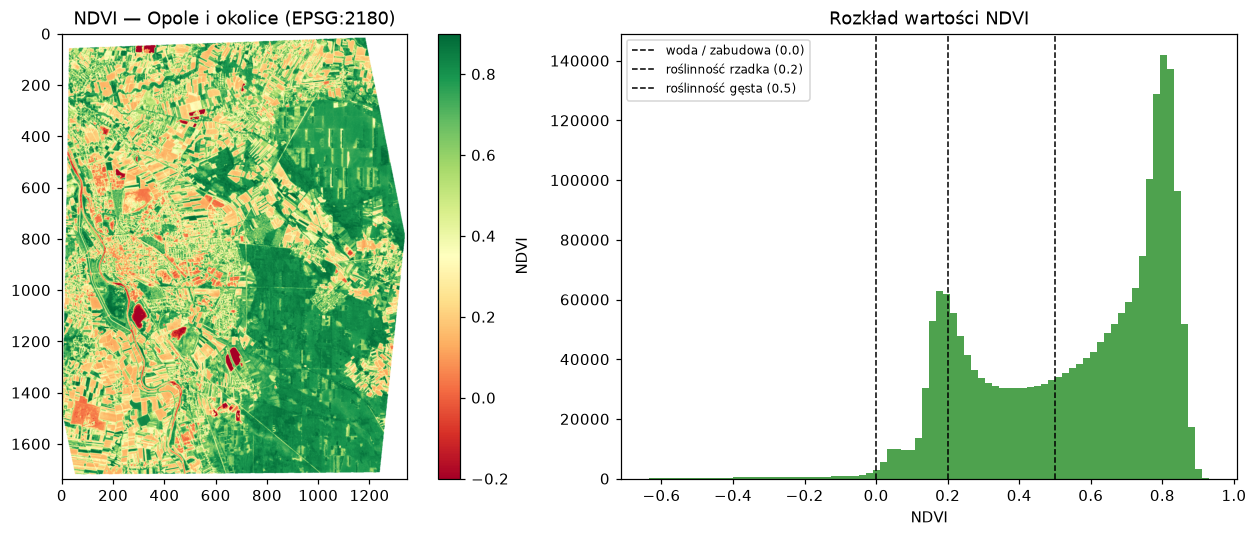

In [7]:
with np.errstate(divide="ignore", invalid="ignore"):
    ndvi = (nir - red) / (nir + red)
ndvi = np.ma.masked_invalid(ndvi)

valid_ndvi = ndvi.compressed()
print(f"Średnie NDVI: {ndvi.mean():.3f}")
print(f"Mediana NDVI: {np.median(valid_ndvi):.3f}")
print(f"Zakres NDVI:  {ndvi.min():.3f} ... {ndvi.max():.3f}")

# Przykładowe piksle: min i max NDVI
ndvi_filled_min = ndvi.filled(np.inf)
ndvi_filled_max = ndvi.filled(-np.inf)
min_rc = np.unravel_index(np.argmin(ndvi_filled_min), ndvi.shape)
max_rc = np.unravel_index(np.argmax(ndvi_filled_max), ndvi.shape)
print(f"Najniższe NDVI {ndvi[min_rc]:.3f} w pikselu {min_rc}")
print(f"Najwyższe NDVI {ndvi[max_rc]:.3f} w pikselu {max_rc}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im = axes[0].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.9)
axes[0].set_title("NDVI — Opole i okolice (EPSG:2180)")
plt.colorbar(im, ax=axes[0], fraction=0.046, label="NDVI")

axes[1].hist(valid_ndvi, bins=80, color="forestgreen", alpha=0.8)
for thr, lbl in [(0.0, "woda / zabudowa (0.0)"), (0.2, "roślinność rzadka (0.2)"), (0.5, "roślinność gęsta (0.5)")]:
    axes[1].axvline(thr, color="black", linestyle="--", linewidth=1, label=lbl)
axes[1].set_title("Rozkład wartości NDVI")
axes[1].set_xlabel("NDVI")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

**B7. Klasyfikacja i powierzchnie w hektarach**

Dyskretyzujemy `ndvi` za pomocą `np.digitize` na 4 klasy pokrycia terenu i przeliczamy liczbę pikseli na hektary (`1 ha = 10 000 m²`).

Powierzchnia piksela: 100.0 m² (EPSG:2180)
                                  Klasa  Liczba pikseli  Powierzchnia [ha]  Udział [%]
0                       0: Woda (< 0.0)           17876             178.76        0.84
1  1: Zabudowa / goła gleba (0.0 – 0.2)          247865            2478.65       11.71
2      2: Rzadka roślinność (0.2 – 0.5)          544724            5447.24       25.74
3           3: Gęsta roślinność (> 0.5)         1305382           13053.82       61.70


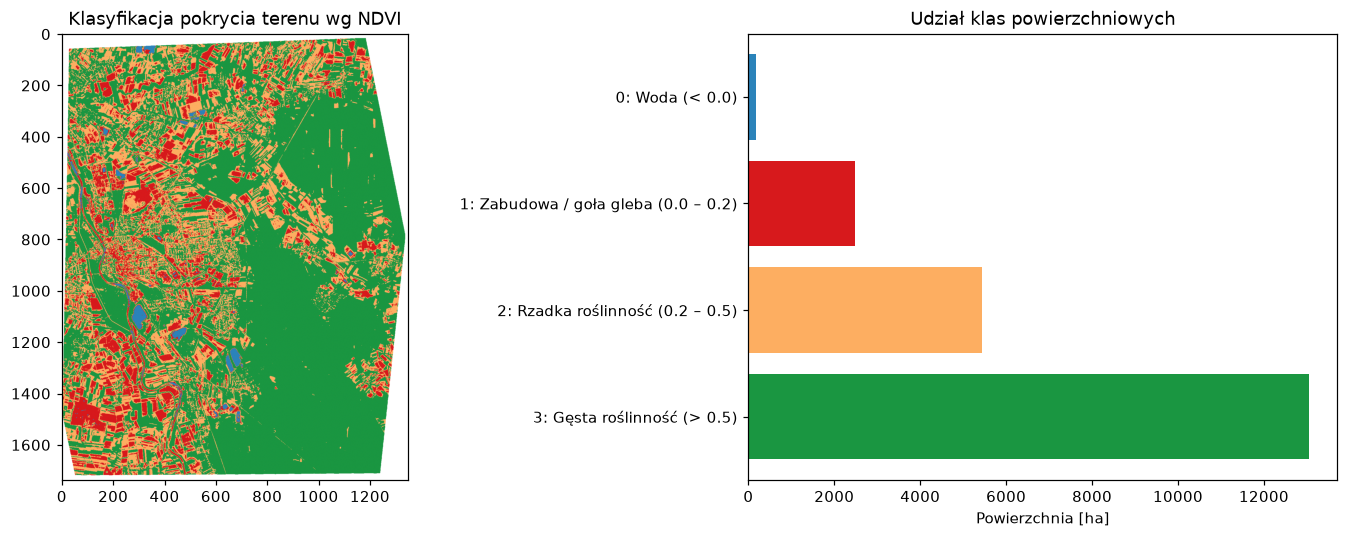

In [8]:
bins = [0.0, 0.2, 0.5]
class_labels = [
    "0: Woda (< 0.0)",
    "1: Zabudowa / goła gleba (0.0 – 0.2)",
    "2: Rzadka roślinność (0.2 – 0.5)",
    "3: Gęsta roślinność (> 0.5)",
]

classes = np.digitize(ndvi.filled(np.nan), bins=bins)
classes = np.ma.masked_where(ndvi.mask, classes)

pixel_area_m2 = abs(dst_transform.a * dst_transform.e)
counts = np.bincount(classes.compressed(), minlength=4)
area_ha = counts * pixel_area_m2 / 10_000
share_pct = 100 * counts / counts.sum()

summary_classes = pd.DataFrame({
    "Klasa": class_labels,
    "Liczba pikseli": counts,
    "Powierzchnia [ha]": np.round(area_ha, 2),
    "Udział [%]": np.round(share_pct, 2),
})
print(f"Powierzchnia piksela: {pixel_area_m2:.1f} m² ({dst_crs})")
display(summary_classes)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cmap_cls = plt.matplotlib.colors.ListedColormap(["#2b83ba", "#d7191c", "#fdae61", "#1a9641"])
axes[0].imshow(classes, cmap=cmap_cls, vmin=0, vmax=3)
axes[0].set_title("Klasyfikacja pokrycia terenu wg NDVI")

axes[1].barh(class_labels, area_ha, color=["#2b83ba", "#d7191c", "#fdae61", "#1a9641"])
axes[1].set_xlabel("Powierzchnia [ha]")
axes[1].set_title("Udział klas powierzchniowych")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

**B8. Statystyki strefowe dla dzielnic (GeoPandas + Rasterio)**

Łączymy dane wektorowe (`dane/opole_districts.geojson`) z rastrem NDVI za pomocą `rasterio.mask.mask`. Sprawdzamy też pokrycie (`coverage`) każdej dzielnicy zasięgiem sceny — dla poligonów pokrytych w mniej niż 50% nie uznajemy średniej za reprezentatywną.

Dzielnice o pokryciu < 50%: 12 z 29
                     name  coverage  ndvi_mean
10               Grudzice  0.999834   0.717100
15               Nadodrze  1.000637   0.661198
13                 Malina  0.999947   0.539318
9               Grotowice  0.848640   0.509162
11    Kolonia GosÅ‚awicka  0.999938   0.491877
8              Groszowice  1.000336   0.464360
12             Krzanowice  1.000164   0.463550
0          Armii Krajowej  1.000344   0.451176
16  Nowa WieÅ› KrÃ³lewska  0.999591   0.425046
23               WrÃ³blin  0.788356   0.424604


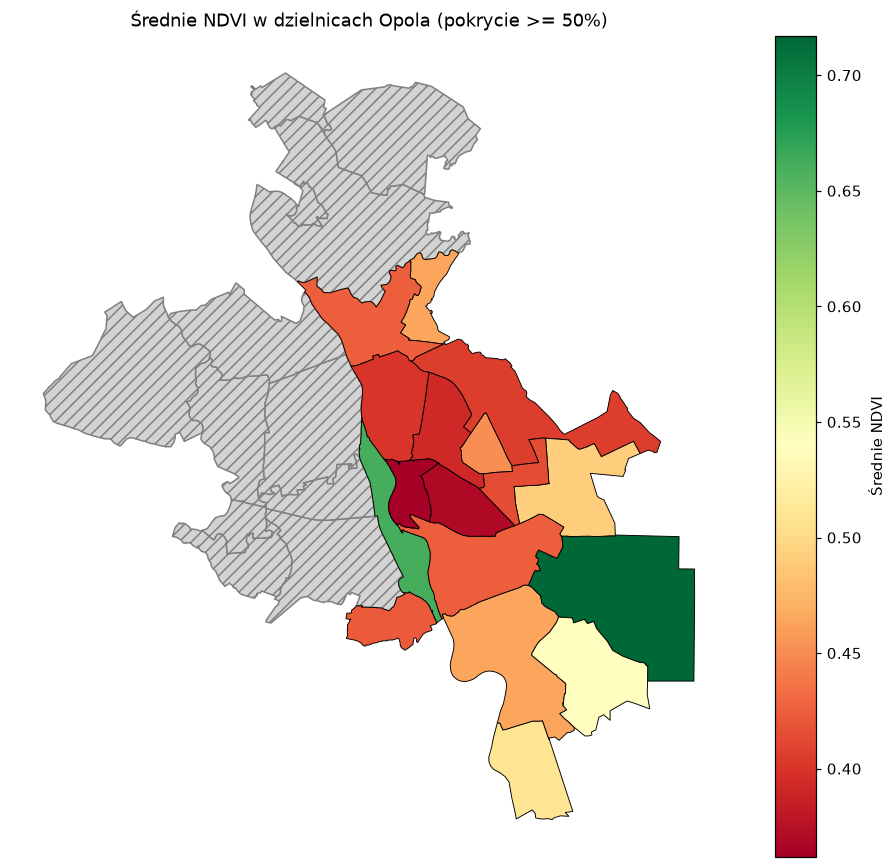

In [9]:
zones = gpd.read_file(DISTRICTS_PATH).to_crs(dst_crs)
pixel_area = abs(dst_transform.a * dst_transform.e)

mem_profile = {
    "driver": "GTiff",
    "height": height,
    "width": width,
    "count": 1,
    "dtype": "float32",
    "crs": dst_crs,
    "transform": dst_transform,
    "nodata": np.nan,
}

with MemoryFile() as memfile:
    with memfile.open(**mem_profile) as mem_dst:
        mem_dst.write(ndvi.filled(np.nan).astype("float32"), 1)
    with memfile.open() as src:
        for i, zone in zones.iterrows():
            try:
                clipped, _ = rasterio.mask.mask(src, [zone.geometry], crop=True, nodata=np.nan)
                values = clipped[np.isfinite(clipped)]
                coverage = values.size * pixel_area / zone.geometry.area
                ndvi_mean = float(values.mean()) if values.size > 0 else np.nan
            except ValueError:
                # Poligon poza zasięgiem rastra
                coverage = 0.0
                ndvi_mean = np.nan
            zones.loc[i, "coverage"] = coverage
            zones.loc[i, "ndvi_mean"] = ndvi_mean

zones["reliable"] = zones["coverage"] >= 0.5
low_cov = int((~zones["reliable"]).sum())
print(f"Dzielnice o pokryciu < 50%: {low_cov} z {len(zones)}")

reliable_zones = zones[zones["reliable"]].sort_values("ndvi_mean", ascending=False)
display(reliable_zones[["name", "coverage", "ndvi_mean"]].head(10))

fig, ax = plt.subplots(figsize=(9, 8))
if (~zones["reliable"]).any():
    zones[~zones["reliable"]].plot(ax=ax, color="lightgray", edgecolor="gray", hatch="///", label="Pokrycie < 50%")
if zones["reliable"].any():
    zones[zones["reliable"]].plot(
        ax=ax,
        column="ndvi_mean",
        cmap="RdYlGn",
        legend=True,
        edgecolor="black",
        linewidth=0.6,
        legend_kwds={"label": "Średnie NDVI"},
    )
ax.set_title("Średnie NDVI w dzielnicach Opola (pokrycie >= 50%)" if zones["reliable"].any() else "Dzielnice Opola poza zasięgiem sceny")
ax.set_axis_off()
plt.tight_layout()
plt.show()

if not zones["reliable"].any():
    from shapely.geometry import box
    # Demonstracja rasterio.mask.mask na przykładowym poligonie wewnątrz zasięgu sceny
    minx, miny, maxx, maxy = rasterio.transform.array_bounds(height, width, dst_transform)
    cx, cy = (minx + maxx) / 2, (miny + maxy) / 2
    dx, dy = (maxx - minx) * 0.25, (maxy - miny) * 0.25
    sample_aoi = gpd.GeoDataFrame(
        {"name": ["Przykładowy obszar (środek sceny)"]},
        geometry=[box(cx - dx, cy - dy, cx + dx, cy + dy)],
        crs=dst_crs,
    )
    with MemoryFile() as memfile:
        with memfile.open(**mem_profile) as mem_dst:
            mem_dst.write(ndvi.filled(np.nan).astype("float32"), 1)
        with memfile.open() as src:
            clipped, _ = rasterio.mask.mask(src, [sample_aoi.geometry.iloc[0]], crop=True, nodata=np.nan)
            vals = clipped[np.isfinite(clipped)]
            print(f"Przykładowa strefa w zasięgu sceny: pikseli={vals.size}, średnie NDVI={vals.mean():.3f}")

**B9. Zapis wyniku do GeoTIFF i weryfikacja**

Zapisujemy wynik do `wyniki/ndvi.tif` w typie `float32` (wartości ułamkowe z przedziału `[-1, 1]`) z `nodata=np.nan` i kompresją `deflate`.

In [10]:
ndvi_out_path = OUT_DIR / "ndvi.tif"

with rasterio.open(B04_PATH) as src:
    profile = src.profile.copy()

profile.update(
    crs=dst_crs,
    transform=dst_transform,
    width=width,
    height=height,
    dtype="float32",
    count=1,
    nodata=np.nan,
    compress="deflate",
)

with rasterio.open(ndvi_out_path, "w", **profile) as dst:
    dst.write(ndvi.filled(np.nan).astype("float32"), 1)
    dst.set_band_description(1, "NDVI")

# Zapis statystyk dzielnic do GeoJSON
zones_out_path = OUT_DIR / "ndvi_districts.geojson"
zones.to_file(zones_out_path, driver="GeoJSON")

# Weryfikacja zapisanego pliku GeoTIFF
with rasterio.open(ndvi_out_path) as check:
    arr_check = check.read(1, masked=True)
    print("Zapisano:", ndvi_out_path)
    print("CRS:", check.crs, "| Kształt:", check.shape, "| Dtype:", check.dtypes[0])
    print("Nodata:", check.nodata, "| Opis pasma:", check.descriptions[0])
    print(f"Zakres odczytany: {arr_check.min():.3f} ... {arr_check.max():.3f}")

Zapisano: wyniki/ndvi.tif
CRS: EPSG:2180 | Kształt: (1736, 1348) | Dtype: float32
Nodata: nan | Opis pasma: NDVI
Zakres odczytany: -0.636 ... 0.931


**Podsumowanie części B:** `rasterio.open` → metadane i transformacja afiniczna → `read(masked=True)` → `reproject` do `EPSG:2180` → algebra NumPy (NDVI) → klasyfikacja `np.digitize` → statystyki strefowe `rasterio.mask.mask` → eksport do GeoTIFF (`wyniki/ndvi.tif`).